# Homework 1 - Aprendizagem

>Teresa Matos- ist1106009   
>Francisco Morão - ist1106067   
>Grupo 46  

## II. Programming

Consider the heart-disease.csv dataset available at the course webpage’s homework tab.
Using sklearn, apply a 5-fold stratified cross-validation with shuffling (random_state=0) for the
assessment of predictive models along this section.

1) Compare the performance of a 𝑘𝑁𝑁 with 𝑘 = 5 and a naïve Bayes with Gaussian
assumption (consider all remaining parameters as default):

a. [1.0v] Plot two boxplots with the fold accuracies for each classifier. Is there one
more stable than the other regarding performance? Why do you think that is the
case? Explain.


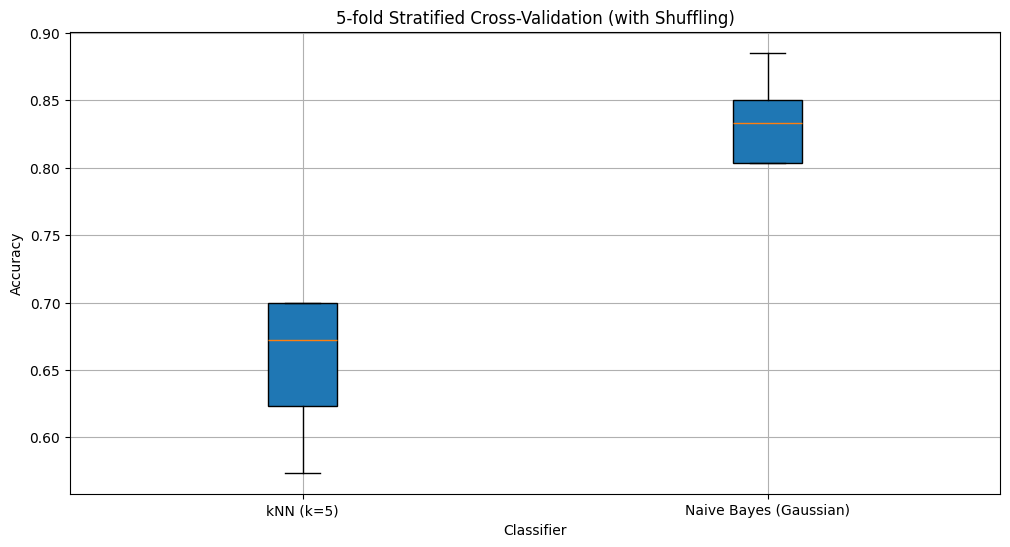

In [33]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('heart-disease.csv')

# Define the feature set and the target variable
X = df.drop(columns='target')  # Features
y = df['target']  # Target variable

# Initialize the stratified 5-fold cross-validation with shuffling
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

classifiers = [KNeighborsClassifier(n_neighbors=5), GaussianNB()]
classifier_names = ['kNN (k=5)', 'Naive Bayes (Gaussian)']

classifier_accuracies = []
for classifier in classifiers:
    accuracies = cross_val_score(classifier, X, y, cv=stratified_kfold)
    classifier_accuracies.append(accuracies)

plt.figure(figsize=(12, 6))
plt.boxplot(classifier_accuracies, patch_artist=True)
plt.xticks(np.arange(1, len(classifier_names) + 1), classifier_names)
plt.xlabel('Classifier')
plt.ylabel('Accuracy')
plt.title('5-fold Stratified Cross-Validation (with Shuffling)')
plt.grid(True)
plt.show()

##### Explicaçao:
Sim, existe um classificador mais estável que o outro relativamente a sua performance. Neste caso o mais estável sera o Naive Bayes Gaussian. Isto porque a estabilidade do classificador pode ser dado por: Stability = 1 - (Biggest_value - Smallest_value), assim o classificador kNN tera uma estabilidade de aproximadamente de 0.87 (1 - 0.7 + 0.57) enquanto que o Naive Bayes tera 0.93 (1 - 0.88 - 0.81). Podemos assim concluir que o Naive Bayes tem uma maior estabilidade relativamente a performance.

Esta conclusão pode-se atribuir ao facto de o Naive Bayes Gaussian assumir uma distribuiçao normal, que apesar de conseguir lidar com todos os tipos de dados, consegue lidar bastante bem quando a independencia entre dados é violada (o que se verifica neste caso) e geralmente este classificador é geralmente menos sensível a ruído quando comparado a kNN. 

b. [1.0v] Report the accuracy of both models, this time scaling the data with a
Min-Max scaler before training the models. Explain the impact that this
preprocessing step has on the performance of each model, providing an
explanation for the results.

kNN Mean Accuracy (scaled): 0.8217
Naive Bayes Mean Accuracy (scaled): 0.8350


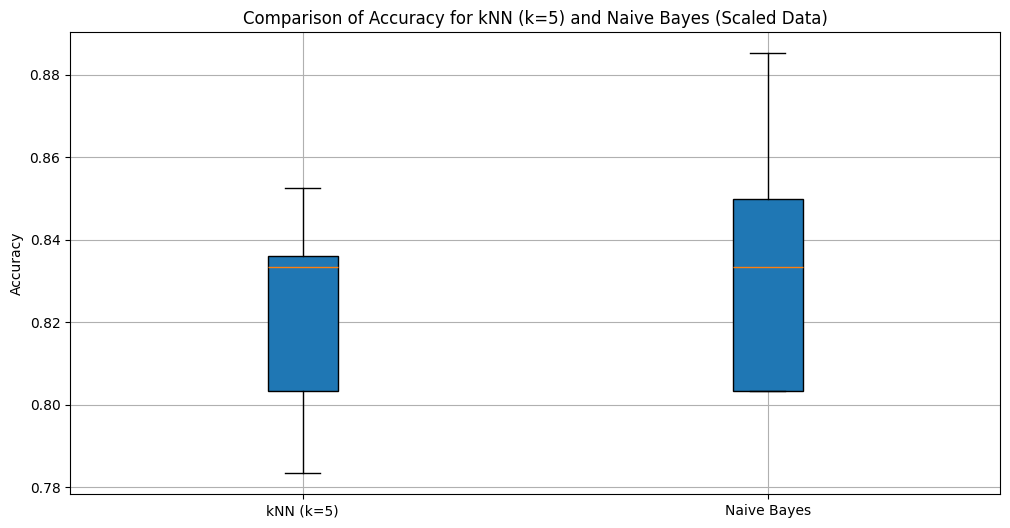

In [34]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt
import numpy as np

# Load the dataset
df = pd.read_csv('heart-disease.csv')

# Define the feature set and the target variable
X = df.drop(columns='target')  # Features
y = df['target']  # Target variable

# Min-Max Scaling of the features
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Define stratified 5-fold cross-validation with shuffling
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# Initialize kNN with k=5 and Naive Bayes
knn = KNeighborsClassifier(n_neighbors=5)
nb = GaussianNB()

# Perform cross-validation for both models
knn_accuracies = cross_val_score(knn, X_scaled, y, cv=stratified_kfold)
nb_accuracies = cross_val_score(nb, X_scaled, y, cv=stratified_kfold)

# Calculate mean accuracies
knn_mean_accuracy = np.mean(knn_accuracies)
nb_mean_accuracy = np.mean(nb_accuracies)

# Print mean accuracies for both models
print(f"kNN Mean Accuracy (scaled): {knn_mean_accuracy:.4f}")
print(f"Naive Bayes Mean Accuracy (scaled): {nb_mean_accuracy:.4f}")

# Plot boxplots of fold accuracies
plt.figure(figsize=(12, 6))
plt.boxplot([knn_accuracies, nb_accuracies], tick_labels=['kNN (k=5)', 'Naive Bayes'], patch_artist=True)
plt.title('Comparison of Accuracy for kNN (k=5) and Naive Bayes (Scaled Data)')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

#### Explicaçao:

kNN é um algoritmo que se baseia nas distâncias entre os dados, por isso ao fazermos um pré-processamento (MIN-MAX scaling) as variáveis são dimensionadas para a mesma escala, o que permite tornar o algoritmo mais equilibrado e mais exato e menos biased perante features que têm naturalmente uma variação maior. No entanto, isto não tem grande impacto num algoritmo como o Naive Bayes, que calcula probabilidades com base nas distribuições.

c. [1.0v] Using scipy, test the hypothesis “the 𝑘𝑁𝑁 model is statistically superior to
naïve Bayes regarding accuracy”, asserting whether it is true.


In [35]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from scipy.stats import ttest_rel

df = pd.read_csv('heart-disease.csv')

# Define the feature set and the target variable
X = df.drop(columns='target')  # Features
y = df['target']  # Target variable

# Assuming `X` is your feature matrix and `y` is your target variable
# Define the classifiers
classifiers = [
    KNeighborsClassifier(n_neighbors=5),  # kNN with k=5
    GaussianNB()  # Naive Bayes with Gaussian assumption
]

# Scaling the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Set up 5-fold stratified cross-validation with shuffling
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# Perform cross-validation for both models
kNN_accuracies = cross_val_score(classifiers[0], X_scaled, y, cv=stratified_kfold)
NB_accuracies = cross_val_score(classifiers[1], X_scaled, y, cv=stratified_kfold)

# Perform the paired t-test
t_stat, p_value = ttest_rel(kNN_accuracies, NB_accuracies, alternative="greater")

# Print the accuracies and statistical test results
print(f"kNN Mean Accuracy: {np.mean(kNN_accuracies):.4f}")
print(f"Naive Bayes Mean Accuracy: {np.mean(NB_accuracies):.4f}")
print(f"p-value: {p_value:.4f}")

# Set the significance level
alpha = 0.1

# Hypothesis testing decision
if p_value < alpha:
    print("kNN is statistically superior to Naive Bayes in terms of accuracy.")
else:
    print("kNN is not statistically superior to Naive Bayes.")


kNN Mean Accuracy: 0.8151
Naive Bayes Mean Accuracy: 0.8350
p-value: 0.8968
kNN is not statistically superior to Naive Bayes.


2) Using a 80-20 train-test split, vary the number of neighbors of a 𝑘𝑁𝑁 classifier using
𝑘 = {1, 5, 10, 20, 30}. Additionally, for each 𝑘, train one classifier using uniform weights
and distance weights.


a. [1.0v] Plot the train and test accuracy for each model. 

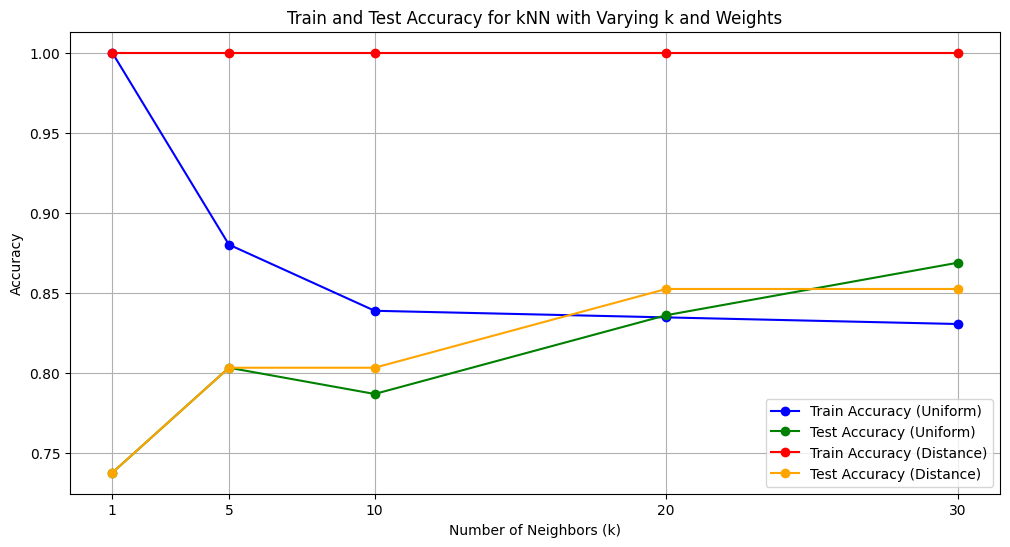

In [36]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('heart-disease.csv')

# Define the feature set and the target variable
X = df.drop(columns='target')  # Features
y = df['target']  # Target variable

# Split the data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Define the values of k to evaluate
k_values = [1, 5, 10, 20, 30]

# Lists to store accuracies
train_accuracies_uniform = []
test_accuracies_uniform = []
train_accuracies_distance = []
test_accuracies_distance = []

# Loop over different values of k
for k in k_values:
    # kNN with uniform weights
    knn_uniform = KNeighborsClassifier(n_neighbors=k, weights='uniform')
    knn_uniform.fit(X_train, y_train)
    
    # kNN with distance weights
    knn_distance = KNeighborsClassifier(n_neighbors=k, weights='distance')
    knn_distance.fit(X_train, y_train)
    
    # Predict and evaluate for uniform weights
    y_train_pred_uniform = knn_uniform.predict(X_train)
    y_test_pred_uniform = knn_uniform.predict(X_test)
    
    train_accuracies_uniform.append(accuracy_score(y_train, y_train_pred_uniform))
    test_accuracies_uniform.append(accuracy_score(y_test, y_test_pred_uniform))
    
    # Predict and evaluate for distance weights
    y_train_pred_distance = knn_distance.predict(X_train)
    y_test_pred_distance = knn_distance.predict(X_test)
    
    train_accuracies_distance.append(accuracy_score(y_train, y_train_pred_distance))
    test_accuracies_distance.append(accuracy_score(y_test, y_test_pred_distance))

# Plotting the results
plt.figure(figsize=(12, 6))

# Plot train and test accuracy for uniform weights
plt.plot(k_values, train_accuracies_uniform, label='Train Accuracy (Uniform)', marker='o', color='blue')
plt.plot(k_values, test_accuracies_uniform, label='Test Accuracy (Uniform)', marker='o', color='green')

# Plot train and test accuracy for distance weights
plt.plot(k_values, train_accuracies_distance, label='Train Accuracy (Distance)', marker='o', color='red')
plt.plot(k_values, test_accuracies_distance, label='Test Accuracy (Distance)', marker='o', color='orange')

# Add labels and legend
plt.title('Train and Test Accuracy for kNN with Varying k and Weights')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

b. [1.5v] Explain the impact of increasing the neighbors on the generalization ability of
the models.


O aumento de vizinhos vai provocar underfitting do modelo, ou seja, o modelo irá deixar de conseguir capturar corretamente a relação entre dados, devido ao excesso de ruído e complexidade, levando à uma má performance e a impossibilidade de generalização de dados.

3) [1.5v] Considering the unique properties of the heart-disease.csv dataset, identify two
possible difficulties of the naïve Bayes model used in the previous exercises when learning
from the given dataset.

Naïve Bayes models, especially those with Gaussian assumptions (as used in the previous exercises), have some intrinsic limitations when dealing with real-world datasets like the heart-disease.csv dataset. Based on the characteristics of this dataset, here are two possible difficulties that Naïve Bayes might encounter:

1. Independence Assumption Violation
Naïve Bayes assumes that all features (predictors) are conditionally independent given the class label. In practice, this assumption is rarely true, and the heart-disease.csv dataset is likely to have correlated features.

Example of Feature Correlations:

Features like age and cholesterol (chol) may be correlated since cholesterol levels tend to increase with age.
Similarly, chest pain type (cp) and exercise-induced angina (exang) are likely related, as individuals with certain types of chest pain may be more prone to developing angina during exercise.
In reality, these features are not independent. Naïve Bayes will treat them as if they are independent, which can lead to incorrect probability estimates and negatively affect model performance.

Impact on Model: When there are significant correlations between features, the independence assumption becomes invalid, and Naïve Bayes may fail to capture the underlying relationships in the data, leading to suboptimal predictions. This can manifest as lower accuracy, especially compared to models like decision trees or kNN that do not rely on this assumption.

2. Handling of Continuous Variables (Gaussian Assumption)
Naïve Bayes with the Gaussian assumption models continuous features by assuming that they follow a normal (Gaussian) distribution. However, real-world datasets like heart-disease.csv often have continuous variables that do not perfectly follow a Gaussian distribution.

Example of Non-Normal Data:

Age: The distribution of age in the dataset might be skewed or have a bimodal distribution depending on the demographics of the patients.
Cholesterol (chol): Cholesterol levels might also show skewness or outliers, as extreme values are common in medical datasets.
Resting blood pressure (trestbps): Blood pressure measurements may have a skewed distribution rather than a normal bell curve.
Impact on Model: If the continuous features in the dataset do not follow a normal distribution, the Gaussian Naïve Bayes model will poorly approximate the true distribution of the data. This misfit between the assumed Gaussian distribution and the actual distribution can lead to inaccurate conditional probabilities and, therefore, poor classification performance.

Conclusion:
Independence Assumption Violation: The correlations between features in the heart-disease dataset (like age, cholesterol, chest pain, and exercise-induced angina) challenge the independence assumption of Naïve Bayes, leading to incorrect probability estimations.

Non-Gaussian Continuous Features: The Gaussian Naïve Bayes model assumes that continuous features follow a normal distribution. If features like age, cholesterol, and resting blood pressure are skewed or have outliers, the Gaussian assumption becomes problematic, reducing model effectiveness.

These difficulties highlight why Naïve Bayes might struggle with datasets like heart-disease.csv, where feature correlations and non-Gaussian distributions are likely present. More flexible models like decision trees, random forests, or support vector machines could better capture the relationships in this dataset